# EuroSAT RGB - Two Layer CNN baseline 

In [28]:
%pip install matplotlib

from pathlib import Path
from torchvision.datasets import ImageFolder

train_path = Path("data/train")
if not train_path.is_dir():
    train_path = Path("../../data/train")

train_data = ImageFolder(train_path)
image, label = train_data[0]

print(f"Training images: {len(train_data):,}")
print(f"Classes: {len(train_data.classes)}")
print(f"First image: {image.size}, {train_data.classes[label]}")


# Quick check that notebook can find the training dataset and open an image 

  Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-macosx_10_13_universal2.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl (284 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp312-cp312-macosx_10_13_universal2.whl (3.1 MB)
Using cached kiwisolver-1.5.1-cp312-cp312-macosx_11_0_arm64.whl (64 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]
Note: you may need to restart the kernel to use u

Creating training and validation split. 

Initially I wanted to do 5 fold stratified cross validation but thought this would take too long on my laptop so opted for 80/20 split cross validation and if two good configurations give similar validation scores then I’ll consider doing the k fold cross validation. The 80/20 split is also similar to what they did in the paper. 

So i should have 17,280 images for training and 4320 images for validation.
Used 'stratify' to keep the proportions of the 10 classes similar in both sets. Chose random state = 7

In [2]:
# Preparing training and validation data
%pip install scikit-learn
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

train_indices, val_indices = train_test_split(
    range(len(train_data)),
    test_size=0.20,
    random_state=7,
    stratify=train_data.targets,
)

tuning_train = Subset(train_data, train_indices)
validation = Subset(train_data, val_indices)

print(f"Training during tuning: {len(tuning_train):,}")
print(f"Validation: {len(validation):,}")

Note: you may need to restart the kernel to use updated packages.
Training during tuning: 17,280
Validation: 4,320


## Starting data

To start with since I only have 17,280 images I'm going to start with batch size of 32 as memory on my laptop probably isn't that great and then later on might compare a batch size of 64.  

In [3]:
# Check one batch 
from torch.utils.data import DataLoader
from torchvision.transforms import ToTensor

train_data.transform = ToTensor()

train_loader = DataLoader(tuning_train, batch_size=32, shuffle=True)
val_loader = DataLoader(validation, batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print(images.shape, labels.shape)

torch.Size([32, 3, 64, 64]) torch.Size([32])


Build CNN
Starting choice of 16 and 32 filters. Mayber lateer might try 8 and 16 to see if a smaller model trains faster and keeps similar validation accuracy. 
First layer takes the 3 RGB channels and produces a 16 feature map
Second layer takes those 16 ,aps and produces 32
ReLU sets negative values to zero and each MaxPool2d(2) halves the width and height so the maps go from 64x64 to 32x32 to 16x16
Then flatter, puts the feature values into on list per image and 'Linear' turn that list into 10 class scores. 

In [9]:
import torch
from torch import nn

model = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.Flatten(),
    nn.Linear(32 * 16 * 16, 10),
)

with torch.no_grad(): #torchnograd allows to check output shape without tracking the calculations needed for training 
    scores = model(images)

print(scores.shape)

torch.Size([32, 10])


Training loop (below) updates weighs once per batch so 17,280/32 = 540 times it updates the weights.
Then we multiply each batch's average loss by its image count so the final average gives every image equal weight. 
Validation loop uses argmax(dim=1) to pick the highest scoring class for each image and checks it against the actual label

## Number of Epochs 

Want to first check how long 1 epoch takes 

In [8]:
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Train for one epoch.
model.train()
total_loss = 0.0
training_count = 0

for batch_images, batch_labels in train_loader:
    optimizer.zero_grad()
    scores = model(batch_images)
    loss = loss_function(scores, batch_labels)
    loss.backward()
    optimizer.step()

    batch_count = batch_labels.size(0)
    total_loss += loss.item() * batch_count
    training_count += batch_count

# Measure validation accuracy.
model.eval()
correct = 0
validation_count = 0

with torch.no_grad():
    for batch_images, batch_labels in val_loader:
        scores = model(batch_images)
        predictions = scores.argmax(dim=1)
        correct += (predictions == batch_labels).sum().item()
        validation_count += batch_labels.size(0)

print(f"Training images seen: {training_count:,}")
print(f"Average training loss: {total_loss / training_count:.3f}")
print(f"Validation images seen: {validation_count:,}")
print(f"Validation accuracy: {correct / validation_count:.1%}")

Training images seen: 17,280
Average training loss: 1.269
Validation images seen: 4,320
Validation accuracy: 65.0%


1 epoch only took 22 seconds so now I'll reset the weights and do 5 epochs

In [ ]:
from time import perf_counter

loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
num_epochs = 5

for epoch in range(6, 11):
    model.train()
    total_loss = 0.0
    training_count = 0
    start_time = perf_counter()

    for batch_images, batch_labels in train_loader:
        optimizer.zero_grad()
        scores = model(batch_images)
        loss = loss_function(scores, batch_labels)
        loss.backward()
        optimizer.step()

        batch_count = batch_labels.size(0)
        total_loss += loss.item() * batch_count
        training_count += batch_count

    training_seconds = perf_counter() - start_time

    model.eval()
    correct = 0
    validation_count = 0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            scores = model(batch_images)
            predictions = scores.argmax(dim=1)
            correct += (predictions == batch_labels).sum().item()
            validation_count += batch_labels.size(0)

    print(
        f"Epoch {epoch}/{num_epochs} | "
        f"Training loss: {total_loss / training_count:.3f} | "
        f"Validation accuracy: {correct / validation_count:.1%} | "
        f"Training time: {training_seconds:.1f}s"
    )

Epoch 1/5 | Training loss: 1.295 | Validation accuracy: 66.0% | Training time: 20.0s
Epoch 2/5 | Training loss: 0.870 | Validation accuracy: 71.8% | Training time: 21.2s
Epoch 3/5 | Training loss: 0.707 | Validation accuracy: 71.2% | Training time: 18.6s
Epoch 4/5 | Training loss: 0.629 | Validation accuracy: 79.2% | Training time: 18.7s
Epoch 5/5 | Training loss: 0.568 | Validation accuracy: 77.3% | Training time: 20.3s


Can see that validation accuracy increases on average as epochs increase but in the last epoch it fell so might run again with more epochs and see if this keeps going up and epoch 5 was a dud or if it tails off after 4 epochs. 
Training loss = measures how far CNN's predictions are from the correct labels on the images it trains on. Cross-entropy loss drops when the CNN gives more confidence to the correct class and it penalises confident mistakes more heavily. 
So will now continue to train through epochs 6 to 11 so we have done 10 epochs and see if the accuracy keeps incresaing.

In [11]:
from time import perf_counter

loss_function = nn.CrossEntropyLoss()
num_epochs = 10

for epoch in range(6, num_epochs + 1):
    model.train()
    total_loss = 0.0
    training_count = 0
    start_time = perf_counter()

    for batch_images, batch_labels in train_loader:
        optimizer.zero_grad()
        scores = model(batch_images)
        loss = loss_function(scores, batch_labels)
        loss.backward()
        optimizer.step()

        batch_count = batch_labels.size(0)
        total_loss += loss.item() * batch_count
        training_count += batch_count

    training_seconds = perf_counter() - start_time

    model.eval()
    correct = 0
    validation_count = 0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            scores = model(batch_images)
            predictions = scores.argmax(dim=1)
            correct += (predictions == batch_labels).sum().item()
            validation_count += batch_labels.size(0)

    print(
        f"Epoch {epoch}/{num_epochs} | "
        f"Training loss: {total_loss / training_count:.3f} | "
        f"Validation accuracy: {correct / validation_count:.1%} | "
        f"Training time: {training_seconds:.1f}s"
    )

Epoch 6/10 | Training loss: 0.523 | Validation accuracy: 75.5% | Training time: 19.6s
Epoch 7/10 | Training loss: 0.484 | Validation accuracy: 77.9% | Training time: 20.3s
Epoch 8/10 | Training loss: 0.445 | Validation accuracy: 80.0% | Training time: 19.6s
Epoch 9/10 | Training loss: 0.427 | Validation accuracy: 81.4% | Training time: 19.0s
Epoch 10/10 | Training loss: 0.394 | Validation accuracy: 79.4% | Training time: 21.0s


So we can see that epoch 9 was the best so far but it dropped in epoch 10, This one drop however is too little evidence to conclude the model is overfitting. I might try run it again with the 10 epochs from fresh to see if i get similar results for where the best epoch to stop on is. 

In [12]:
from time import perf_counter

import torch
from torch import nn

# Use a fixed seed so you can repeat this run.
# Your existing training and validation split stays the same.
torch.manual_seed(123)

# Create a new CNN with fresh random weights.
repeat_model = nn.Sequential(
    nn.Conv2d(3, 16, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 16 * 16, 10),
)

loss_function = nn.CrossEntropyLoss()
repeat_optimizer = torch.optim.Adam(repeat_model.parameters(), lr=0.001)

num_epochs = 10
validation_accuracies = []

for epoch in range(1, num_epochs + 1):
    repeat_model.train()
    total_loss = 0.0
    training_count = 0
    start_time = perf_counter()

    for batch_images, batch_labels in train_loader:
        repeat_optimizer.zero_grad()
        scores = repeat_model(batch_images)
        loss = loss_function(scores, batch_labels)
        loss.backward()
        repeat_optimizer.step()

        batch_count = batch_labels.size(0)
        total_loss += loss.item() * batch_count
        training_count += batch_count

    training_seconds = perf_counter() - start_time

    repeat_model.eval()
    correct = 0
    validation_count = 0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            scores = repeat_model(batch_images)
            predictions = scores.argmax(dim=1)
            correct += (predictions == batch_labels).sum().item()
            validation_count += batch_labels.size(0)

    validation_accuracy = correct / validation_count
    validation_accuracies.append(validation_accuracy)

    print(
        f"Epoch {epoch}/{num_epochs} | "
        f"Training loss: {total_loss / training_count:.3f} | "
        f"Validation accuracy: {validation_accuracy:.1%} | "
        f"Training time: {training_seconds:.1f}s"
    )

best_accuracy = max(validation_accuracies)
best_epoch = validation_accuracies.index(best_accuracy) + 1
print(f"\nBest repeat result: epoch {best_epoch}, {best_accuracy:.1%}")

Epoch 1/10 | Training loss: 1.295 | Validation accuracy: 61.9% | Training time: 20.9s
Epoch 2/10 | Training loss: 0.892 | Validation accuracy: 71.9% | Training time: 18.6s
Epoch 3/10 | Training loss: 0.768 | Validation accuracy: 72.1% | Training time: 20.5s
Epoch 4/10 | Training loss: 0.680 | Validation accuracy: 75.5% | Training time: 18.8s
Epoch 5/10 | Training loss: 0.609 | Validation accuracy: 77.3% | Training time: 18.4s
Epoch 6/10 | Training loss: 0.565 | Validation accuracy: 75.5% | Training time: 18.6s
Epoch 7/10 | Training loss: 0.508 | Validation accuracy: 80.2% | Training time: 19.2s
Epoch 8/10 | Training loss: 0.482 | Validation accuracy: 80.4% | Training time: 18.3s
Epoch 9/10 | Training loss: 0.453 | Validation accuracy: 79.5% | Training time: 22.3s
Epoch 10/10 | Training loss: 0.424 | Validation accuracy: 79.9% | Training time: 21.2s

Best repeat result: epoch 8, 80.4%


After this result I'm going to go with number of epochs to be 9 since it had the highest accuracy of both those runs and also the dip in the second run from 8 to 9 wasn't very much (0.2pp). 

## Varying the Learning Rate

- 0.0001
- 0.0005
- 0.001 
- 0.002
- 0.003

I'm going to test all these learning rates and train five fresh CNNs for 10 epochs each. 
If two learning rates finish close together, I'm going to repeat those two with a second seed such as 124 and see whether the same rate does well again. 

Model settings are:

- **Number of Epochs** = 10
- **Learning Rate** = Varying
- **Batch Size** = 32
- **Filters** = 16->32 
- **Optimiser** = Adam

In [20]:
from time import perf_counter

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision.transforms import ToTensor

train_data.transform = ToTensor()
batch_size = 32
num_epochs = 10

validation_loader = DataLoader(
    validation, batch_size=batch_size, shuffle=False
)

def build_cnn(filters=(16, 32)):
    first_filters, second_filters = filters

    return nn.Sequential(
        nn.Conv2d(3, first_filters, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(first_filters, second_filters, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(second_filters * 16 * 16, 10),
    )


def run_trial(learning_rate, seed=123,batch_size=32,*,filters=(16, 32),
    optimizer_class=torch.optim.Adam,
    **optimizer_options,
):
    torch.manual_seed(seed)
    model = build_cnn(filters)
    optimizer = optimizer_class(
        model.parameters(),
        lr=learning_rate,
        **optimizer_options,
    )
    loss_function = nn.CrossEntropyLoss()

    shuffle_generator = torch.Generator().manual_seed(seed)
    training_loader = DataLoader(
        tuning_train,
        batch_size=batch_size,
        shuffle=True,
        generator=shuffle_generator,
    )

    history = []
    print(
        f"\n{optimizer_class.__name__} | Learning rate {learning_rate:g} | "
        f"Batch size {batch_size} | Filters {filters[0]} → {filters[1]} | Seed {seed}"
    )

    for epoch in range(1, num_epochs + 1):
        model.train()
        total_loss = 0.0
        start_time = perf_counter()

        for images, labels in training_loader:
            optimizer.zero_grad()
            scores = model(images)
            loss = loss_function(scores, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)

        training_seconds = perf_counter() - start_time
        training_loss = total_loss / len(tuning_train)

        model.eval()
        correct = 0

        with torch.no_grad():
            for images, labels in validation_loader:
                predictions = model(images).argmax(dim=1)
                correct += (predictions == labels).sum().item()

        accuracy = correct / len(validation)
        history.append({
            "epoch": epoch,
            "training_loss": training_loss,
            "validation_accuracy": accuracy,
            "training_seconds": training_seconds,
        })

        print(
            f"Epoch {epoch:2d}/{num_epochs} | "
            f"Loss {training_loss:.3f} | "
            f"Validation accuracy {accuracy:.1%} | "
            f"Training time {training_seconds:.1f}s"
        )

    return history



In [ ]:
learning_rate_results = {}

for learning_rate in learning_rates:
    learning_rate_results[learning_rate] = run_trial(learning_rate)

print("\nLearning-rate summary")
print(f"{'Rate':>8} {'Best epoch':>11} {'Best val acc':>14} {'Training time':>15}")

for learning_rate, history in learning_rate_results.items():
    best = max(history, key=lambda row: row["validation_accuracy"])
    total_seconds = sum(row["training_seconds"] for row in history)

    print(
        f"{learning_rate:>8g} {best['epoch']:>11d} "
        f"{best['validation_accuracy']:>14.1%} {total_seconds:>13.1f}s"
    )

0.001 and 0.003 were just simply not as good and then 0.0005, 0.001, 0.002 all hit similar accuracy peaks but 0.002 fell off by epoch 10.
The bigger updates in 0.02 also seemed to make the accuracy bounce around a bit more so I think I’ll ditch this one. 

So since 0.005 and 0.001 reached pretty similar peak accuracies of 80.9% and 81.0% respectively I wanted to retest these with different seed. 

In [16]:
repeat_rates = [0.0005, 0.001]
learning_rate_repeat_results = {}

for rate in repeat_rates:
    learning_rate_repeat_results[rate] = run_trial(rate, seed=124)

learning_rate_average_results = {}

print("\nValidation accuracy across both seeds")
print(f"{'Rate':>8} {'Epoch':>5} {'Seed 123':>10} {'Seed 124':>10} {'Mean':>10}")

for rate in repeat_rates:
    original_history = learning_rate_results[rate]
    repeat_history = learning_rate_repeat_results[rate]
    averages = []

    for original, repeat in zip(original_history, repeat_history, strict=True):
        epoch = original["epoch"]
        original_accuracy = original["validation_accuracy"]
        repeat_accuracy = repeat["validation_accuracy"]
        mean_accuracy = (original_accuracy + repeat_accuracy) / 2

        averages.append({
            "epoch": epoch,
            "mean_validation_accuracy": mean_accuracy,
        })

        print(
            f"{rate:>8g} {epoch:>5d} "
            f"{original_accuracy:>10.2%} {repeat_accuracy:>10.2%} "
            f"{mean_accuracy:>10.2%}"
        )

    learning_rate_average_results[rate] = averages

print("\nBest epoch for each learning rate across both seeds")

for rate, averages in learning_rate_average_results.items():
    best = max(averages, key=lambda row: row["mean_validation_accuracy"])
    print(
        f"Adam {rate:g} | Epoch {best['epoch']} | "
        f"Mean validation accuracy {best['mean_validation_accuracy']:.2%}"
    )


Adam learning rate 0.0005 | Seed 124
Epoch  1/10 | Loss 1.393 | Validation accuracy 58.2% | Training time 19.6s
Epoch  2/10 | Loss 0.987 | Validation accuracy 64.1% | Training time 19.1s
Epoch  3/10 | Loss 0.865 | Validation accuracy 63.5% | Training time 18.9s
Epoch  4/10 | Loss 0.798 | Validation accuracy 72.5% | Training time 24.1s
Epoch  5/10 | Loss 0.733 | Validation accuracy 72.2% | Training time 19.0s
Epoch  6/10 | Loss 0.682 | Validation accuracy 71.4% | Training time 19.7s
Epoch  7/10 | Loss 0.639 | Validation accuracy 75.1% | Training time 20.0s
Epoch  8/10 | Loss 0.599 | Validation accuracy 79.7% | Training time 19.3s
Epoch  9/10 | Loss 0.572 | Validation accuracy 79.1% | Training time 19.1s
Epoch 10/10 | Loss 0.549 | Validation accuracy 78.1% | Training time 19.6s

Adam learning rate 0.001 | Seed 124
Epoch  1/10 | Loss 1.275 | Validation accuracy 64.1% | Training time 19.9s
Epoch  2/10 | Loss 0.884 | Validation accuracy 68.7% | Training time 21.3s
Epoch  3/10 | Loss 0.742 

As we can see from the results it looks like the learning rate of 0.001 is the best one so this is what I will carry on with. 

## Varying the Batch Size with updated learnning rate 

- 32
- 64

Whether larger batches save computing time while keeping similar accuracy. If 64 is faster and gives similar validation accuracy then I'll try batch size of 128 as well.  

Model settings are:
- **Number of Epochs** = 10
- **Learning Rate** = 0.001
- **Batch Size** = Varying
- **Filters** = 16->32 
- **Optimiser** = Adam

In [21]:
batch_test_rate = 0.001
batch_test_seeds = (123, 124)

# Reuse the existing batch-size-32 runs.
batch_32_results = {
    123: learning_rate_results[batch_test_rate],
    124: learning_rate_repeat_results[batch_test_rate],
}

# Train only the two new batch-size-64 runs.
batch_64_results = {}

for trial_seed in batch_test_seeds:
    batch_64_results[trial_seed] = run_trial(
        learning_rate=batch_test_rate,
        seed=trial_seed,
        batch_size=64,
        filters=(16, 32),
        optimizer_class=torch.optim.Adam,
    )

print("\nValidation accuracy by epoch")
print(
    f"{'Epoch':>5} | {'32 / 123':>8} {'64 / 123':>8} | "
    f"{'32 / 124':>8} {'64 / 124':>8} | {'32 mean':>8} {'64 mean':>8}"
)

for epoch_index in range(10):
    acc_32_123 = batch_32_results[123][epoch_index]["validation_accuracy"]
    acc_64_123 = batch_64_results[123][epoch_index]["validation_accuracy"]
    acc_32_124 = batch_32_results[124][epoch_index]["validation_accuracy"]
    acc_64_124 = batch_64_results[124][epoch_index]["validation_accuracy"]

    mean_32 = (acc_32_123 + acc_32_124) / 2
    mean_64 = (acc_64_123 + acc_64_124) / 2

    print(
        f"{epoch_index + 1:>5} | {acc_32_123:>8.2%} {acc_64_123:>8.2%} | "
        f"{acc_32_124:>8.2%} {acc_64_124:>8.2%} | "
        f"{mean_32:>8.2%} {mean_64:>8.2%}"
    )

print("\nTotal training time over 10 epochs, excluding validation")
print(f"{'Seed':>5} | {'Batch 32':>10} | {'Batch 64':>10}")

for trial_seed in batch_test_seeds:
    time_32 = sum(row["training_seconds"] for row in batch_32_results[trial_seed])
    time_64 = sum(row["training_seconds"] for row in batch_64_results[trial_seed])
    print(f"{trial_seed:>5} | {time_32:>9.1f}s | {time_64:>9.1f}s")


Adam | Learning rate 0.001 | Batch size 64 | Filters 16 → 32 | Seed 123
Epoch  1/10 | Loss 1.384 | Validation accuracy 63.5% | Training time 18.7s
Epoch  2/10 | Loss 0.934 | Validation accuracy 67.9% | Training time 17.4s
Epoch  3/10 | Loss 0.793 | Validation accuracy 73.8% | Training time 17.6s
Epoch  4/10 | Loss 0.696 | Validation accuracy 77.9% | Training time 17.7s
Epoch  5/10 | Loss 0.634 | Validation accuracy 79.4% | Training time 17.5s
Epoch  6/10 | Loss 0.603 | Validation accuracy 78.8% | Training time 20.1s
Epoch  7/10 | Loss 0.556 | Validation accuracy 79.9% | Training time 16.9s
Epoch  8/10 | Loss 0.528 | Validation accuracy 75.6% | Training time 16.8s
Epoch  9/10 | Loss 0.518 | Validation accuracy 77.8% | Training time 16.5s
Epoch 10/10 | Loss 0.479 | Validation accuracy 82.5% | Training time 16.4s

Adam | Learning rate 0.001 | Batch size 64 | Filters 16 → 32 | Seed 124
Epoch  1/10 | Loss 1.385 | Validation accuracy 61.8% | Training time 16.6s
Epoch  2/10 | Loss 0.970 | Va

If i was set on epoch 9 then I would choose batch size 32 but if i chose epochs to be 10 then i would choose batch size of 64. 
However it didn't save that much time but maybe if we were scaling this up then this would be a bigger difference and so i would opt for batch size 64 and epochs 10. 

I'm going to carry on with my experiment and change the batch size to 64 and use 10 epochs. 

## Varying the number of filters 

- 8 -> 16 
- 16 -> 32 
- 32 -> 64

See whether smaller CNN can get similar accuracy with fewer parameters and less training time 

Model settings are:
- **Number of Epochs** = 10
- **Learning Rate** = 0.001
- **Batch Size** = 64
- **Filters** = Varying
- **Optimiser** = Adam

In [22]:
filter_settings = [(8, 16), (16, 32), (32, 64)]
filter_test_seeds = (123, 124)

# Reuse the reference runs from the batch-size experiment.
filter_results = {(16, 32): batch_64_results}

# Train the smaller and larger CNNs from fresh weights.
for filters in [(8, 16), (32, 64)]:
    filter_results[filters] = {}

    for trial_seed in filter_test_seeds:
        filter_results[filters][trial_seed] = run_trial(
            learning_rate=0.001,
            seed=trial_seed,
            batch_size=64,
            filters=filters,
            optimizer_class=torch.optim.Adam,
        )

# Average validation accuracy across the two seeds at each epoch.
filter_mean_accuracy = {}

for filters in filter_settings:
    runs = filter_results[filters]
    filter_mean_accuracy[filters] = [
        (run_123["validation_accuracy"] + run_124["validation_accuracy"]) / 2
        for run_123, run_124 in zip(runs[123], runs[124], strict=True)
    ]

print("\nMean validation accuracy across seeds 123 and 124")
print(f"{'Epoch':>5} | {'8 → 16':>9} | {'16 → 32':>9} | {'32 → 64':>9}")

for epoch_index in range(10):
    print(
        f"{epoch_index + 1:>5} | "
        f"{filter_mean_accuracy[(8, 16)][epoch_index]:>9.2%} | "
        f"{filter_mean_accuracy[(16, 32)][epoch_index]:>9.2%} | "
        f"{filter_mean_accuracy[(32, 64)][epoch_index]:>9.2%}"
    )

print("\nFilter comparison")
print(
    f"{'Filters':>8} | {'Parameters':>10} | {'Best epoch':>10} | "
    f"{'Best mean':>9} | {'Epoch 10':>9} | {'Mean train time':>15}"
)

for filters in filter_settings:
    model_for_count = build_cnn(filters)
    parameter_count = sum(
        parameter.numel() for parameter in model_for_count.parameters()
    )

    accuracies = filter_mean_accuracy[filters]
    best_accuracy = max(accuracies)
    best_epoch = accuracies.index(best_accuracy) + 1

    runs = filter_results[filters]
    mean_training_seconds = sum(
        row["training_seconds"]
        for trial_seed in filter_test_seeds
        for row in runs[trial_seed]
    ) / len(filter_test_seeds)

    filter_label = f"{filters[0]} → {filters[1]}"
    print(
        f"{filter_label:>8} | {parameter_count:>10,} | {best_epoch:>10} | "
        f"{best_accuracy:>9.2%} | {accuracies[-1]:>9.2%} | "
        f"{mean_training_seconds:>14.1f}s"
    )


Adam | Learning rate 0.001 | Batch size 64 | Filters 8 → 16 | Seed 123
Epoch  1/10 | Loss 1.472 | Validation accuracy 60.7% | Training time 15.1s
Epoch  2/10 | Loss 1.035 | Validation accuracy 65.7% | Training time 12.0s
Epoch  3/10 | Loss 0.914 | Validation accuracy 68.8% | Training time 13.4s
Epoch  4/10 | Loss 0.838 | Validation accuracy 71.0% | Training time 13.5s
Epoch  5/10 | Loss 0.769 | Validation accuracy 71.4% | Training time 12.0s
Epoch  6/10 | Loss 0.727 | Validation accuracy 74.5% | Training time 12.1s
Epoch  7/10 | Loss 0.682 | Validation accuracy 75.7% | Training time 12.8s
Epoch  8/10 | Loss 0.649 | Validation accuracy 76.3% | Training time 12.0s
Epoch  9/10 | Loss 0.631 | Validation accuracy 77.0% | Training time 11.9s
Epoch 10/10 | Loss 0.603 | Validation accuracy 76.9% | Training time 12.6s

Adam | Learning rate 0.001 | Batch size 64 | Filters 8 → 16 | Seed 124
Epoch  1/10 | Loss 1.497 | Validation accuracy 59.9% | Training time 12.3s
Epoch  2/10 | Loss 1.087 | Vali

The 16-32 filter test I had already got from the results when doing the batch testing. 
8-16 has lower accuracy across most epochs so lets not do this option 
16-32 and 32-64 had similar scores for everything with the 32-64 coming out slightly better but 16-32 was 27% faster so if you were optimising for time I'd choose the smaller CNN. 
I want to keep both in the tests for the different optimiser functions to see if there is a more clear winner. 

## Varying the Optimiser Function 

- Adam
- SGD
- RMSProp 

Model settings are:
- **Number of Epochs** = 10
- **Learning Rate** = 0.001
- **Batch Size** = 64
- **Filters** = 16->32 and 32->64
- **Optimiser** = Varying


In [23]:
optimizer_test_filters = [(16, 32), (32, 64)]
optimizer_test_seeds = (123, 124, 125)
optimizer_test_rate = 0.001
optimizer_test_batch_size = 64

optimizers_to_test = {
    "Adam": torch.optim.Adam,
    "SGD": torch.optim.SGD,
    "RMSprop": torch.optim.RMSprop,
}

optimizer_results = {}

for filters in optimizer_test_filters:
    for optimizer_name, optimizer_class in optimizers_to_test.items():
        runs = {}

        for trial_seed in optimizer_test_seeds:
            if optimizer_name == "Adam" and trial_seed in (123, 124):
                history = filter_results[filters][trial_seed]

                print(
                    f"\nAdam | Learning rate {optimizer_test_rate:g} | "
                    f"Batch size {optimizer_test_batch_size} | "
                    f"Filters {filters[0]} → {filters[1]} | "
                    f"Seed {trial_seed} (reused)",
                    flush=True,
                )

                for row in history:
                    print(
                        f"Epoch {row['epoch']:2d}/{len(history)} | "
                        f"Loss {row['training_loss']:.3f} | "
                        f"Validation accuracy {row['validation_accuracy']:.1%} | "
                        f"Training time {row['training_seconds']:.1f}s",
                        flush=True,
                    )
            else:
                history = run_trial(
                    learning_rate=optimizer_test_rate,
                    seed=trial_seed,
                    batch_size=optimizer_test_batch_size,
                    filters=filters,
                    optimizer_class=optimizer_class,
                )

            runs[trial_seed] = history

        optimizer_results[(filters, optimizer_name)] = runs


Adam | Learning rate 0.001 | Batch size 64 | Filters 16 → 32 | Seed 123 (reused)
Epoch  1/10 | Loss 1.384 | Validation accuracy 63.5% | Training time 18.7s
Epoch  2/10 | Loss 0.934 | Validation accuracy 67.9% | Training time 17.4s
Epoch  3/10 | Loss 0.793 | Validation accuracy 73.8% | Training time 17.6s
Epoch  4/10 | Loss 0.696 | Validation accuracy 77.9% | Training time 17.7s
Epoch  5/10 | Loss 0.634 | Validation accuracy 79.4% | Training time 17.5s
Epoch  6/10 | Loss 0.603 | Validation accuracy 78.8% | Training time 20.1s
Epoch  7/10 | Loss 0.556 | Validation accuracy 79.9% | Training time 16.9s
Epoch  8/10 | Loss 0.528 | Validation accuracy 75.6% | Training time 16.8s
Epoch  9/10 | Loss 0.518 | Validation accuracy 77.8% | Training time 16.5s
Epoch 10/10 | Loss 0.479 | Validation accuracy 82.5% | Training time 16.4s

Adam | Learning rate 0.001 | Batch size 64 | Filters 16 → 32 | Seed 124 (reused)
Epoch  1/10 | Loss 1.385 | Validation accuracy 61.8% | Training time 16.6s
Epoch  2/10

In [24]:
optimizer_mean_accuracy = {}

print("Validation accuracy and training time")
print(
    f"{'Filters':>8} | {'Optimizer':>9} | "
    f"{'123 @10':>8} {'124 @10':>8} {'125 @10':>8} | "
    f"{'Mean @10':>8} | {'Best epoch':>10} {'Best mean':>9} | "
    f"{'Mean train':>10}"
)

for (filters, optimizer_name), runs in optimizer_results.items():
    mean_by_epoch = [
        sum(runs[seed][index]["validation_accuracy"] for seed in optimizer_test_seeds)
        / len(optimizer_test_seeds)
        for index in range(num_epochs)
    ]
    optimizer_mean_accuracy[(filters, optimizer_name)] = mean_by_epoch

    best_mean = max(mean_by_epoch)
    best_epoch = mean_by_epoch.index(best_mean) + 1

    mean_training_seconds = sum(
        row["training_seconds"]
        for seed in optimizer_test_seeds
        for row in runs[seed]
    ) / len(optimizer_test_seeds)

    seed_123 = runs[123][-1]["validation_accuracy"]
    seed_124 = runs[124][-1]["validation_accuracy"]
    seed_125 = runs[125][-1]["validation_accuracy"]
    filter_label = f"{filters[0]} → {filters[1]}"

    print(
        f"{filter_label:>8} | {optimizer_name:>9} | "
        f"{seed_123:>8.2%} {seed_124:>8.2%} {seed_125:>8.2%} | "
        f"{mean_by_epoch[-1]:>8.2%} | {best_epoch:>10} {best_mean:>9.2%} | "
        f"{mean_training_seconds:>9.1f}s"
    )
    

Validation accuracy and training time
 Filters | Optimizer |  123 @10  124 @10  125 @10 | Mean @10 | Best epoch Best mean | Mean train
 16 → 32 |      Adam |   82.48%   79.77%   81.90% |   81.38% |         10    81.38% |     171.1s
 16 → 32 |       SGD |   32.01%   34.17%   36.69% |   34.29% |         10    34.29% |     166.8s
 16 → 32 |   RMSprop |   74.38%   61.64%   80.19% |   72.07% |          7    77.59% |     167.6s
 32 → 64 |      Adam |   84.54%   80.00%   78.96% |   81.17% |         10    81.17% |     256.6s
 32 → 64 |       SGD |   36.00%   37.57%   38.68% |   37.42% |         10    37.42% |     254.3s
 32 → 64 |   RMSprop |   77.87%   77.11%   81.30% |   78.76% |          9    79.43% |     273.7s


Can see Adam scored the best so I will keep Adam as the optimiser function. Also it seems the best epoch was mostly at 10 so I will use this and out of the Adam optimisers the mean accuracy at 10 epochs was higher using the 16->32 as the filter layer sizes.  

I've tried in other files varying the padding and also looking at orientation flips of images but the experiments didn't find any improvements so I will now lock in the model settings as:
Model settings are:
- **Number of Epochs** = am going to plot 1-15 
- **Learning Rate** = 0.001
- **Batch Size** = 64
- **Filters** = 16->32
- **Optimiser** = Adam
- **Padding** = 1 



## Overfitting Graph 

I want to use 15 epochs to plot where the overfitting starts appearing using three new unused seeds of 127,128,129 and will plot graphs of each. 

In [26]:
from time import perf_counter

import torch
from torch import nn
from torch.utils.data import DataLoader

long_run_seeds = (127, 128, 129)
long_run_epochs = 15


def run_long_trial(seed):
    torch.manual_seed(seed)
    model = build_cnn(filters=(16, 32))
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    loader = DataLoader(
        tuning_train,
        batch_size=64,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )

    history = []
    print(f"\nSeed {seed}", flush=True)

    for epoch in range(1, long_run_epochs + 1):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        start = perf_counter()

        for images, labels in loader:
            optimizer.zero_grad()
            scores = model(images)
            loss = criterion(scores, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)
            train_correct += (scores.argmax(dim=1) == labels).sum().item()

        training_seconds = perf_counter() - start

        model.eval()
        val_loss_sum = 0.0
        val_correct = 0

        with torch.inference_mode():
            for images, labels in validation_loader:
                scores = model(images)
                val_loss_sum += criterion(scores, labels).item() * labels.size(0)
                val_correct += (scores.argmax(dim=1) == labels).sum().item()

        row = {
            "epoch": epoch,
            "train_loss": train_loss_sum / len(tuning_train),
            "val_loss": val_loss_sum / len(validation),
            "train_accuracy": train_correct / len(tuning_train),
            "val_accuracy": val_correct / len(validation),
        }
        history.append(row)

        print(
            f"Epoch {epoch:2d}/{long_run_epochs} | "
            f"Train loss {row['train_loss']:.3f} | "
            f"Val loss {row['val_loss']:.3f} | "
            f"Train accuracy {row['train_accuracy']:.2%} | "
            f"Val accuracy {row['val_accuracy']:.2%} | "
            f"Train time {training_seconds:.1f}s",
            flush=True,
        )

    return history


long_run_results = {seed: run_long_trial(seed) for seed in long_run_seeds}


Seed 127
Epoch  1/15 | Train loss 1.441 | Val loss 1.144 | Train accuracy 44.76% | Val accuracy 57.04% | Train time 19.6s
Epoch  2/15 | Train loss 0.992 | Val loss 0.877 | Train accuracy 64.40% | Val accuracy 70.44% | Train time 17.8s
Epoch  3/15 | Train loss 0.855 | Val loss 0.826 | Train accuracy 69.92% | Val accuracy 72.71% | Train time 18.0s
Epoch  4/15 | Train loss 0.761 | Val loss 0.767 | Train accuracy 73.23% | Val accuracy 73.01% | Train time 17.3s
Epoch  5/15 | Train loss 0.712 | Val loss 0.769 | Train accuracy 75.14% | Val accuracy 72.29% | Train time 19.4s
Epoch  6/15 | Train loss 0.661 | Val loss 0.675 | Train accuracy 77.25% | Val accuracy 75.72% | Train time 16.4s
Epoch  7/15 | Train loss 0.628 | Val loss 0.640 | Train accuracy 77.89% | Val accuracy 77.25% | Train time 16.2s
Epoch  8/15 | Train loss 0.559 | Val loss 0.657 | Train accuracy 80.63% | Val accuracy 76.92% | Train time 16.1s
Epoch  9/15 | Train loss 0.520 | Val loss 0.717 | Train accuracy 82.22% | Val accuracy

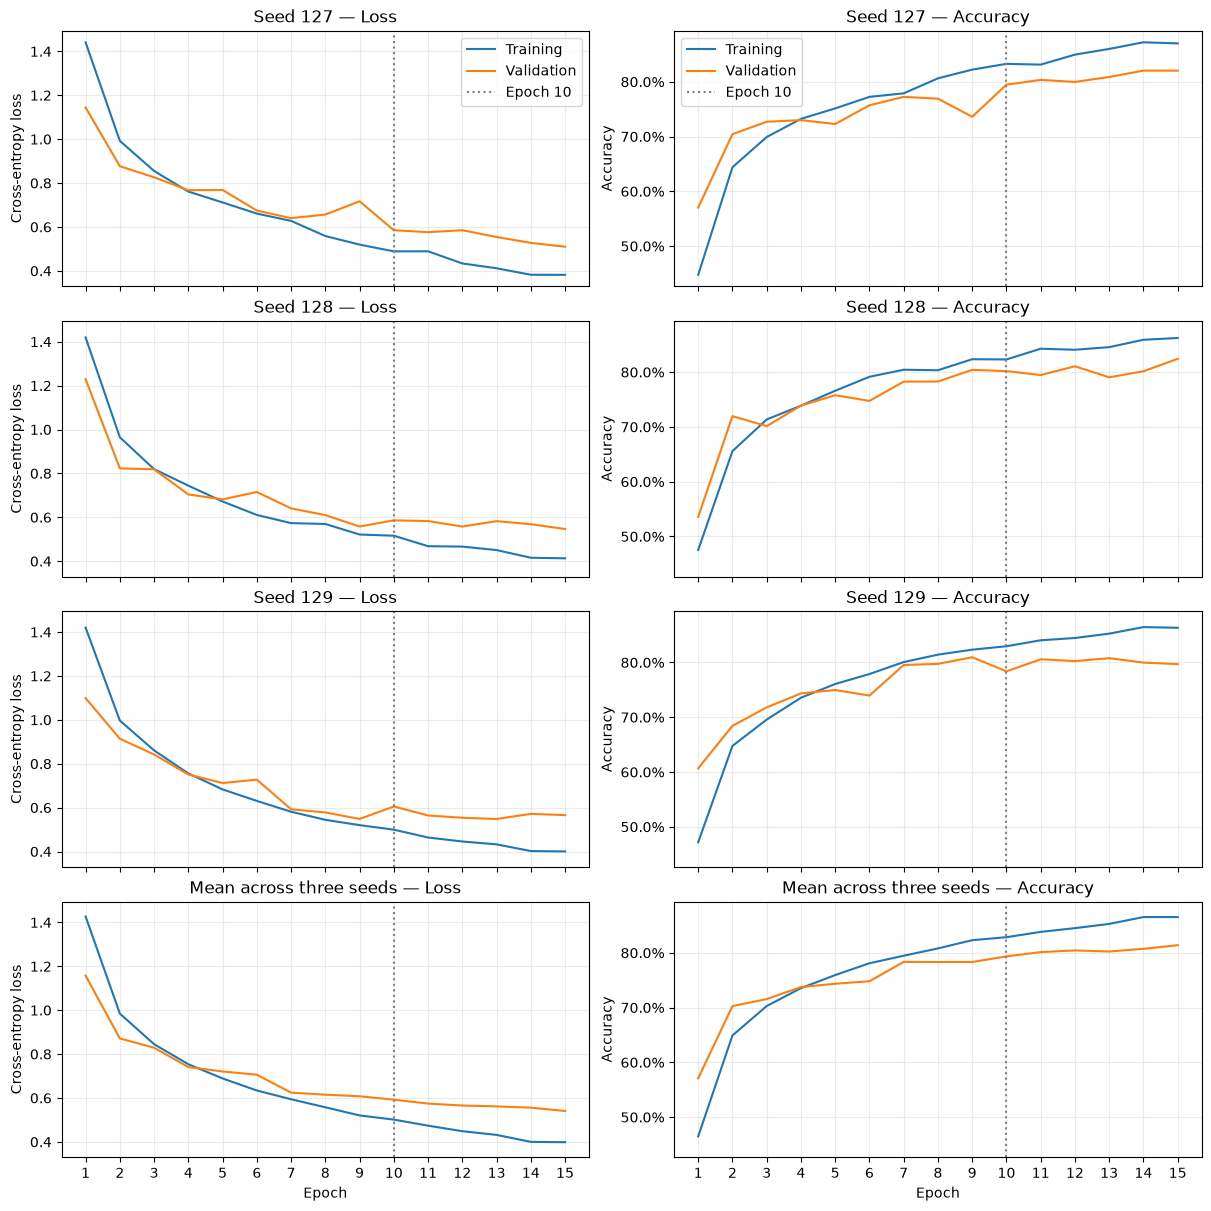


Mean validation results from epoch 10 onward
Epoch 10 | Validation loss 0.592 | Validation accuracy 79.34%
Epoch 11 | Validation loss 0.574 | Validation accuracy 80.13%
Epoch 12 | Validation loss 0.566 | Validation accuracy 80.43%
Epoch 13 | Validation loss 0.562 | Validation accuracy 80.24%
Epoch 14 | Validation loss 0.556 | Validation accuracy 80.73%
Epoch 15 | Validation loss 0.541 | Validation accuracy 81.39%


In [29]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

metric_keys = ("train_loss", "val_loss", "train_accuracy", "val_accuracy")
epoch_numbers = range(1, long_run_epochs + 1)

long_run_means = [
    {
        key: sum(long_run_results[seed][index][key] for seed in long_run_seeds)
        / len(long_run_seeds)
        for key in metric_keys
    }
    for index in range(long_run_epochs)
]

plot_rows = [(f"Seed {seed}", long_run_results[seed]) for seed in long_run_seeds]
plot_rows.append(("Mean across three seeds", long_run_means))

fig, axes = plt.subplots(
    len(plot_rows), 2, figsize=(12, 12),
    sharex=True, sharey="col", constrained_layout=True,
)

for (name, history), (loss_ax, accuracy_ax) in zip(plot_rows, axes, strict=True):
    loss_ax.plot(epoch_numbers, [row["train_loss"] for row in history], label="Training")
    loss_ax.plot(epoch_numbers, [row["val_loss"] for row in history], label="Validation")
    loss_ax.set(title=f"{name} — Loss", ylabel="Cross-entropy loss")

    accuracy_ax.plot(
        epoch_numbers, [row["train_accuracy"] for row in history], label="Training"
    )
    accuracy_ax.plot(
        epoch_numbers, [row["val_accuracy"] for row in history], label="Validation"
    )
    accuracy_ax.set(title=f"{name} — Accuracy", ylabel="Accuracy")
    accuracy_ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

    for ax in (loss_ax, accuracy_ax):
        ax.axvline(10, color="gray", linestyle=":", label="Epoch 10")
        ax.grid(alpha=0.25)

for ax in axes[0]:
    ax.legend()

for ax in axes[-1]:
    ax.set_xlabel("Epoch")
    ax.set_xticks(list(epoch_numbers))

plt.show()

print("\nMean validation results from epoch 10 onward")
for epoch in range(10, long_run_epochs + 1):
    row = long_run_means[epoch - 1]
    print(
        f"Epoch {epoch:2d} | Validation loss {row['val_loss']:.3f} | "
        f"Validation accuracy {row['val_accuracy']:.2%}"
    )

Bit concerned that training past 10 epochs seemed to improve the validation accuracy with an average gain of 2.05 percentage points (79.34% to 89.39%) and mean validation loss fell at every epoch from 0.592 to 0.541. 
So there is no clear sign that overfitting started at epoch 10.

**Variation in Seeds** 
127 and 128 finished with higher validation accuracy at epoch 15 than epoch 10 and seed 129 seemed to plateau a bit after epoch 7. 

**Time**
Doing 15 epochs took significantly more time, 50% more passes through the data are needed so if time is an issue then 10 is still a good number of epochs to use. 


## Another overfitting comparison 

I'm going to do another run with seeds 1,2,3 from epochs 1 - 25 now 

In [30]:
from time import perf_counter

import torch
from torch import nn
from torch.utils.data import DataLoader

extended_seeds = (1, 2, 3)
extended_epochs = 25
extended_results = {}
extended_checkpoints = {}


def run_extended_trial(seed):
    torch.manual_seed(seed)
    model = build_cnn(filters=(16, 32))
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    shuffle_generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        tuning_train,
        batch_size=64,
        shuffle=True,
        generator=shuffle_generator,
    )

    history = []
    print(f"\nSeed {seed}", flush=True)

    for epoch in range(1, extended_epochs + 1):
        model.train()
        train_loss_sum = 0.0
        train_correct = 0
        start = perf_counter()

        for images, labels in train_loader:
            optimizer.zero_grad()
            scores = model(images)
            loss = criterion(scores, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)
            train_correct += (scores.argmax(dim=1) == labels).sum().item()

        training_seconds = perf_counter() - start

        model.eval()
        val_loss_sum = 0.0
        val_correct = 0

        with torch.inference_mode():
            for images, labels in validation_loader:
                scores = model(images)
                val_loss_sum += criterion(scores, labels).item() * labels.size(0)
                val_correct += (scores.argmax(dim=1) == labels).sum().item()

        row = {
            "epoch": epoch,
            "train_loss": train_loss_sum / len(tuning_train),
            "val_loss": val_loss_sum / len(validation),
            "train_accuracy": train_correct / len(tuning_train),
            "val_accuracy": val_correct / len(validation),
            "training_seconds": training_seconds,
        }
        history.append(row)

        print(
            f"Epoch {epoch:2d}/{extended_epochs} | "
            f"Train loss {row['train_loss']:.3f} | "
            f"Val loss {row['val_loss']:.3f} | "
            f"Train accuracy {row['train_accuracy']:.2%} | "
            f"Val accuracy {row['val_accuracy']:.2%} | "
            f"Train time {training_seconds:.1f}s",
            flush=True,
        )

    extended_checkpoints[seed] = {
        "epoch": extended_epochs,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "shuffle_state": shuffle_generator.get_state(),
    }
    return history


for seed in extended_seeds:
    extended_results[seed] = run_extended_trial(seed)


Seed 1
Epoch  1/25 | Train loss 1.476 | Val loss 1.109 | Train accuracy 44.83% | Val accuracy 59.28% | Train time 18.3s
Epoch  2/25 | Train loss 0.952 | Val loss 0.797 | Train accuracy 66.16% | Val accuracy 71.46% | Train time 17.7s
Epoch  3/25 | Train loss 0.796 | Val loss 0.877 | Train accuracy 71.87% | Val accuracy 70.56% | Train time 18.4s
Epoch  4/25 | Train loss 0.723 | Val loss 0.751 | Train accuracy 74.70% | Val accuracy 73.94% | Train time 17.0s
Epoch  5/25 | Train loss 0.650 | Val loss 0.685 | Train accuracy 77.31% | Val accuracy 75.23% | Train time 19.2s
Epoch  6/25 | Train loss 0.609 | Val loss 0.638 | Train accuracy 78.78% | Val accuracy 77.04% | Train time 18.0s
Epoch  7/25 | Train loss 0.552 | Val loss 0.609 | Train accuracy 81.04% | Val accuracy 78.38% | Train time 20.2s
Epoch  8/25 | Train loss 0.538 | Val loss 0.606 | Train accuracy 81.31% | Val accuracy 78.52% | Train time 18.5s
Epoch  9/25 | Train loss 0.500 | Val loss 0.604 | Train accuracy 82.77% | Val accuracy 7

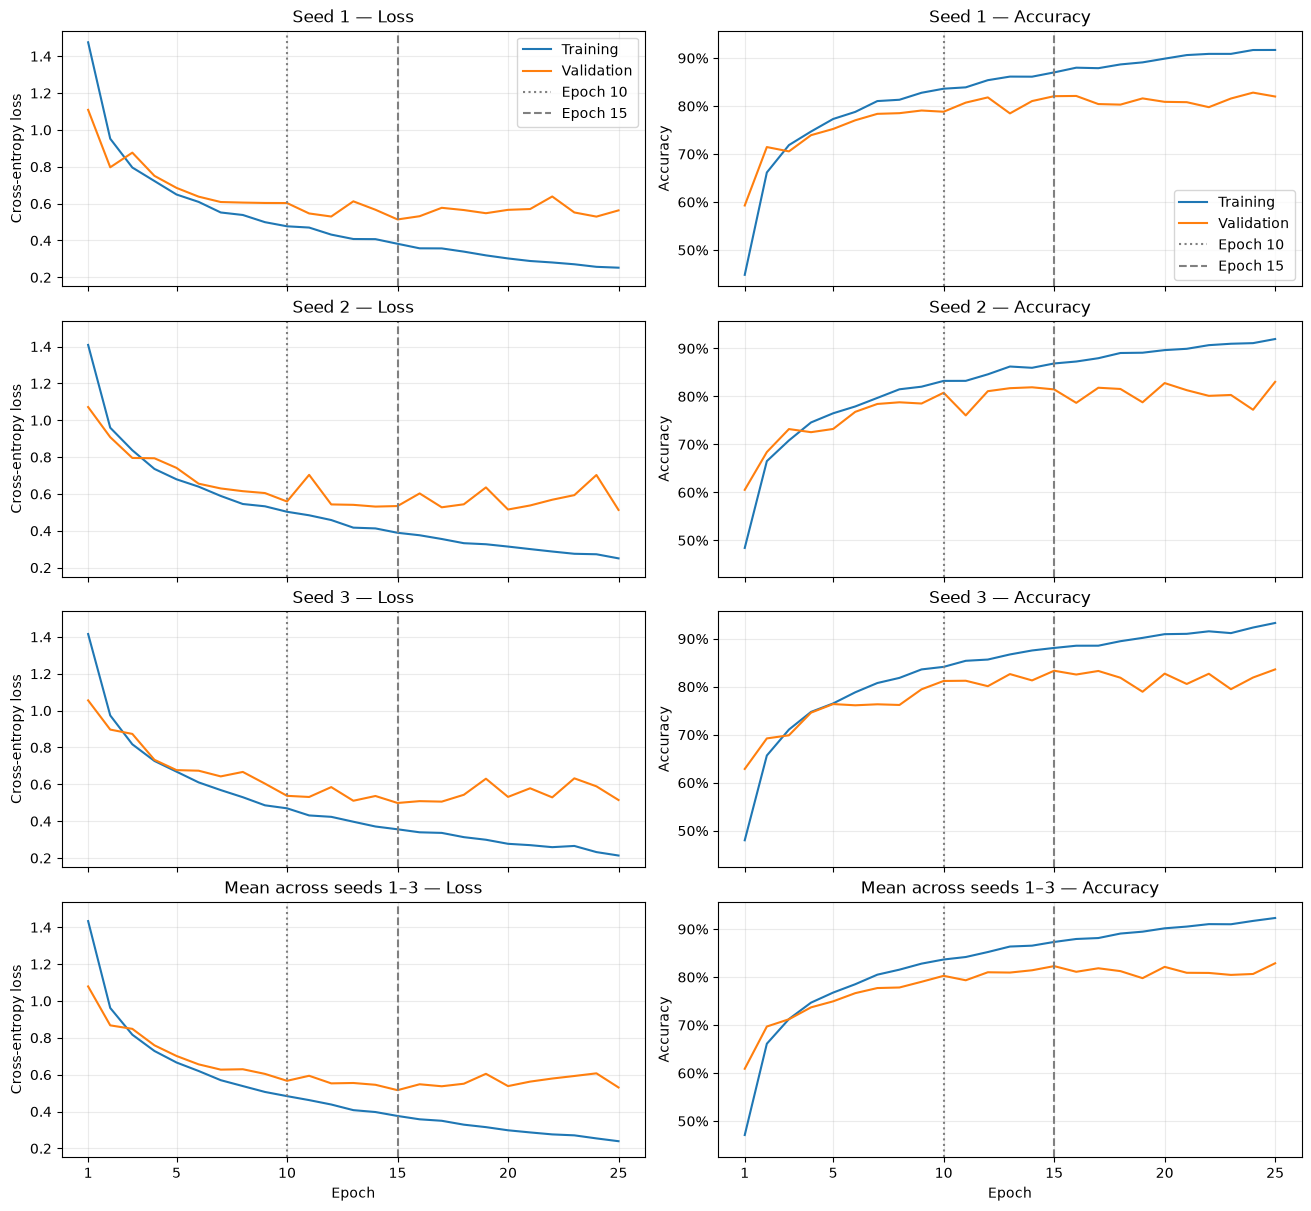

In [31]:
from statistics import mean

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

seeds = (1, 2, 3)
epochs = [row["epoch"] for row in extended_results[seeds[0]]]
metrics = ("train_loss", "val_loss", "train_accuracy", "val_accuracy")

mean_history = [
    {
        metric: mean(extended_results[seed][index][metric] for seed in seeds)
        for metric in metrics
    }
    for index in range(len(epochs))
]

plot_rows = [(f"Seed {seed}", extended_results[seed]) for seed in seeds]
plot_rows.append(("Mean across seeds 1–3", mean_history))

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(13, 12),
    sharex=True,
    sharey="col",
    constrained_layout=True,
)

for (title, history), (loss_ax, accuracy_ax) in zip(plot_rows, axes, strict=True):
    loss_ax.plot(epochs, [row["train_loss"] for row in history], label="Training")
    loss_ax.plot(epochs, [row["val_loss"] for row in history], label="Validation")
    loss_ax.set(title=f"{title} — Loss", ylabel="Cross-entropy loss")

    accuracy_ax.plot(
        epochs, [row["train_accuracy"] for row in history], label="Training"
    )
    accuracy_ax.plot(
        epochs, [row["val_accuracy"] for row in history], label="Validation"
    )
    accuracy_ax.set(title=f"{title} — Accuracy", ylabel="Accuracy")
    accuracy_ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))

    for ax in (loss_ax, accuracy_ax):
        ax.axvline(10, color="gray", linestyle=":", label="Epoch 10")
        ax.axvline(15, color="gray", linestyle="--", label="Epoch 15")
        ax.grid(alpha=0.25)

for ax in axes[0]:
    ax.legend()

for ax in axes[-1]:
    ax.set_xlabel("Epoch")
    ax.set_xticks([1, 5, 10, 15, 20, 25])

plt.show()

### Results - overfitting experiment 

We can see from the graphs that there are some signs of overfitting after epoch 15 but the validation accuracy still improved slightly by epoch 25, at epoch 10, 15, 25 mean validation accuracies are 80.26%, 82.28% and 82.88% respectively. 
So we can see that the CNN does keep getting better at fitting the training images but the gains on the validaiton images become smaller and less consistent. 

The seeds are a bit confusing to be able to tell where overfitting might begin as they all drop and fluctuate at different points. 

I think i might change my number of epohs to 15 actually after seeing this. 